# Multivariate Bayesian Synthetic Control

Standard {term}`synthetic control` builds the counterfactual for a treated unit from a weighted combination of untreated donor units, with weights chosen to reproduce the treated unit's pre-treatment **outcome** {cite}`abadie2010synthetic`. This works well when the outcome path is informative enough to tell good donors from bad ones. It can fail when it is not: several donors can look identical before treatment while differing in characteristics that matter after it.

`MultivariateSyntheticControl` adds extra per-unit **predictors** (for example industry share, exports or unemployment). The donor weights must now reproduce both the treated unit's outcome and its predictors. The counterfactual is still built from the outcome only, so the predictors guide *which donors are chosen* but are never forecast, and they do not need to be observed after treatment.

This notebook uses simulated data with a known true effect to show when the extra predictors help, how to read the output, and what to watch for.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import causalpy as cp
from causalpy.experiments.multivariate_synthetic_control import (
    MultivariateSyntheticControl,
)

In [2]:
%config InlineBackend.figure_format = 'retina'
seed = 4
TRUE_EFFECT = 2.0
sample_kwargs = {
    "draws": 1000,
    "tune": 1500,
    "target_accept": 0.99,
    "random_seed": seed,
    "progressbar": False,
}

## Simulated data

There are ten donor units and one treated unit observed for 60 periods, with the treatment starting at period 40. Every unit's outcome (`gdp`) is made of a common trend plus a **shock that only starts at the treatment time**, to which each unit is exposed to a different degree. The true treatment effect is +2.

The key feature is that before treatment the shock is zero, so a unit's exposure leaves no trace in its pre-treatment `gdp`. All donors have almost the same pre-treatment path, and the outcome alone cannot tell them apart. The treated unit is more exposed than the average donor. Two predictors, `industry` and `exports`, are noisy proxies of exposure. The other two, `irrelevant` and `noise`, carry no information about it.

The data are in **long format**: one row per unit and period, with the outcome and the predictors as columns.

In [3]:
def make_panel(seed, n_time=60, treatment_time=40, n_donors=10):
    rng = np.random.default_rng(seed)
    t = np.arange(n_time)
    common = np.cumsum(rng.normal(size=n_time)) / 3 + np.sin(t / 5)
    shock = np.where(
        t >= treatment_time, 2.0 * (1 - np.exp(-(t - treatment_time) / 6)), 0.0
    )
    donors = [f"c{i}" for i in range(n_donors)]
    exposure = rng.permutation(np.linspace(-2, 4, n_donors))
    a = 10 + rng.normal(0, 0.03, n_donors)
    b = 1 + rng.normal(0, 0.03, n_donors)
    z = rng.normal(size=n_donors)

    def unit_rows(name, a_u, b_u, e_u, z_u, effect):
        return [
            {
                "unit": name,
                "time": i,
                "gdp": a_u
                + b_u * common[i]
                + e_u * shock[i]
                + effect * (i >= treatment_time)
                + rng.normal(0, 0.05),
                "industry": 5 + 2 * e_u + 0.3 * common[i] + rng.normal(0, 0.1),
                "exports": -1 + 1.5 * e_u + 0.2 * common[i] + rng.normal(0, 0.1),
                "irrelevant": z_u + rng.normal(0, 0.1),
                "noise": rng.normal(),
            }
            for i in range(n_time)
        ]

    rows = []
    for k, name in enumerate(donors):
        rows += unit_rows(name, a[k], b[k], exposure[k], z[k], 0.0)
    rows += unit_rows("treated", a.mean(), b.mean(), 2.5, 0.3, TRUE_EFFECT)
    return pd.DataFrame(rows), donors, treatment_time


df, donors, treatment_time = make_panel(seed)
predictors = ["industry", "exports", "irrelevant", "noise"]
df.head()

,unit,time,gdp,industry,exports,irrelevant,noise
0,c0,0,9.877655,0.986632,-4.047186,-0.161602,-0.120949
1,c0,1,10.014002,1.055259,-3.978775,-0.072646,-0.544533
2,c0,2,10.725478,1.059314,-3.731575,-0.143524,0.183393
3,c0,3,11.121888,1.318058,-3.812725,-0.033551,0.115751
4,c0,4,10.654650,1.244659,-4.036710,0.013025,-0.171131


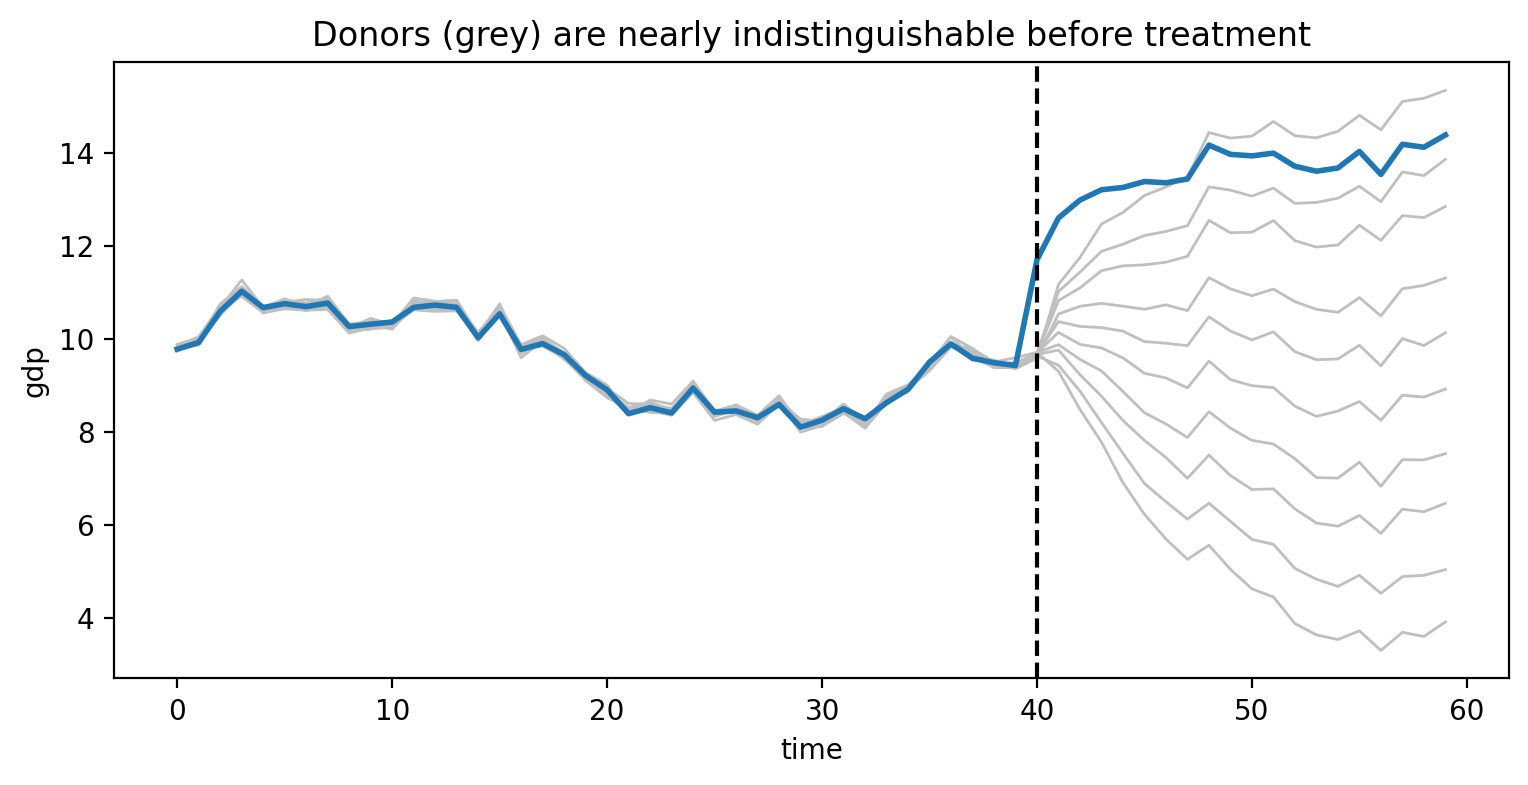

In [4]:
wide = df.pivot(index="time", columns="unit", values="gdp")
fig, ax = plt.subplots(figsize=(9, 4))
wide[donors].plot(ax=ax, color="0.75", legend=False, lw=1)
wide["treated"].plot(ax=ax, color="C0", lw=2, label="treated")
ax.axvline(treatment_time, color="k", ls="--")
ax.set(
    title="Donors (grey) are nearly indistinguishable before treatment",
    xlabel="time",
    ylabel="gdp",
);

## Baseline: outcome-only synthetic control

First fit the standard model, which sees only the outcome. With ten near-identical donors, it has no reason to prefer the donors with the right exposure.

In [5]:
outcome_only = cp.SyntheticControl(
    wide,
    treatment_time=treatment_time,
    control_units=donors,
    treated_units=["treated"],
    model=cp.pymc_models.WeightedSumFitter(sample_kwargs=sample_kwargs),
    min_donor_correlation=-1.0,
).fit()

C:\Users\ZBook\Documents\PyMC\CausalPy\causalpy\experiments\synthetic_control.py:167: UserWarning: Convex hull assumption may be violated: 4 pre-intervention time points (5.0% above, 5.0% below control range). The synthetic control method requires the treated unit to lie within the convex hull of control units. Consider: (1) adding more diverse control units, (2) using a model with an intercept (e.g., ITS with control predictors), or (3) using the Augmented Synthetic Control Method. See glossary term 'Convex hull condition' for more details.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, y_hat_sigma]
Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 88 seconds.
Sampling: [y_hat]
Sampling: [y_hat]
Sampling: [y_hat]
Sampling: [y_hat]
Sampling: [beta, y_hat, y_hat_sigma]
Sampling: [y_hat]
Sampling: [y_hat]


## Multivariate synthetic control

Now fit the multivariate model on the long-format panel. `v_prior="learned"` (the default) lets the model estimate how much weight each predictor gets when matching; `"uniform"` gives every predictor the same weight. We fit both, to compare them.

The predictors are standardised internally using pre-treatment statistics, so they can be on different scales.

In [6]:
def fit_multivariate(v_prior):
    return MultivariateSyntheticControl(
        df,
        treatment_time=treatment_time,
        outcome="gdp",
        predictors=predictors,
        control_units=donors,
        treated_units=["treated"],
        unit_column="unit",
        time_column="time",
        min_donor_correlation=-1.0,
        model=cp.pymc_models.MvWeightedSumFitter(
            v_prior=v_prior, sample_kwargs=sample_kwargs
        ),
    ).fit()


learned = fit_multivariate("learned")
uniform = fit_multivariate("uniform")

C:\Users\ZBook\Documents\PyMC\CausalPy\causalpy\experiments\synthetic_control.py:167: UserWarning: Convex hull assumption may be violated: 4 pre-intervention time points (5.0% above, 5.0% below control range). The synthetic control method requires the treated unit to lie within the convex hull of control units. Consider: (1) adding more diverse control units, (2) using a model with an intercept (e.g., ITS with control predictors), or (3) using the Augmented Synthetic Control Method. See glossary term 'Convex hull condition' for more details.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, sigma_feat, v, y_hat_sigma]
Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 237 seconds.
Sampling: [y_feat, y_hat]
Sampling: [y_hat]
Sampling: [y_hat]
Sampling: [y_hat]
Sampling: [beta, sigma_feat, v, y_feat, y_hat, y_hat_sigma]
Sampling: [y_hat]
Sampling: [y_hat]
C:\Users\ZBook\Documents\PyMC\CausalPy\cau

In [7]:
learned.summary(round_to=2)

==========================MultivariateSyntheticControl==========================
Control units: ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9']
Treated unit: treated
Model coefficients:
  c0  0.0042, 94% HDI [7.1e-06, 0.012]
  c1  0.0044, 94% HDI [4e-07, 0.013]
  c2  0.19, 94% HDI [0.099, 0.27]
  c3  0.13, 94% HDI [0.026, 0.23]
  c4  0.0041, 94% HDI [5.5e-06, 0.011]
  c5  0.2, 94% HDI [0.048, 0.34]
  c6  0.25, 94% HDI [0.13, 0.36]
  c7  0.15, 94% HDI [0.048, 0.24]
  c8  0.0088, 94% HDI [3.5e-06, 0.025]
  c9  0.064, 94% HDI [7e-05, 0.15]
Pre-treatment correlation (treated): 0.9984
Predictor weights (v):
  industry    0.74
  exports     0.26
  irrelevant  0.00077
  noise       0.00039


## The standard CausalPy plot

`MultivariateSyntheticControl` inherits the usual synthetic control figure, so `plot()` works as it does for any other CausalPy experiment. The top panel shows the treated unit and the counterfactual, the middle panel the causal impact, and the bottom panel the cumulative impact. Only the outcome is drawn: the predictors guide the choice of donors but are never forecast, so they do not appear here.

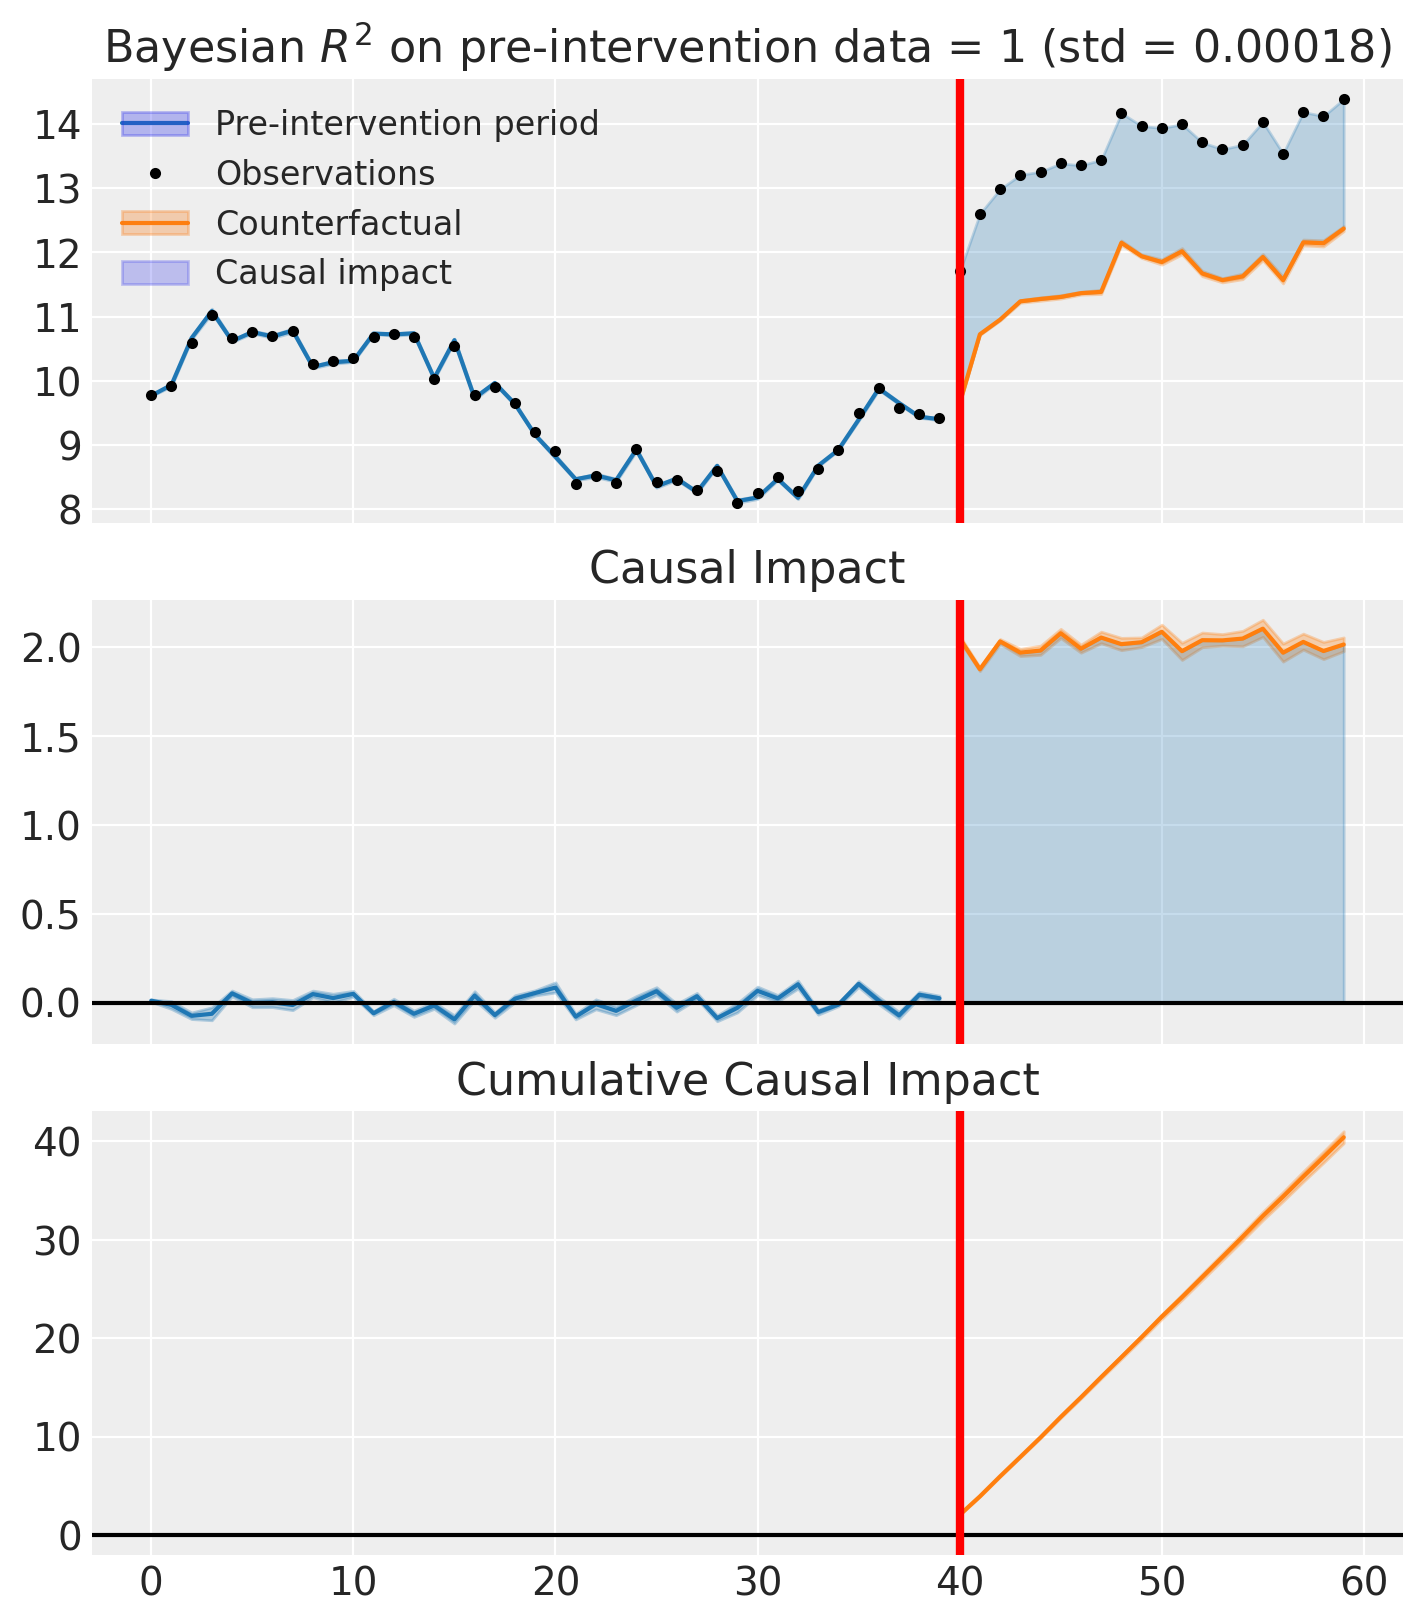

In [8]:
fig, ax = learned.plot()

## Comparing the counterfactuals

The plots show the treated unit (black), the model's counterfactual (blue, with a 94% interval), and the treatment time. The gap between the black line and the blue band after the dashed line is the estimated effect.

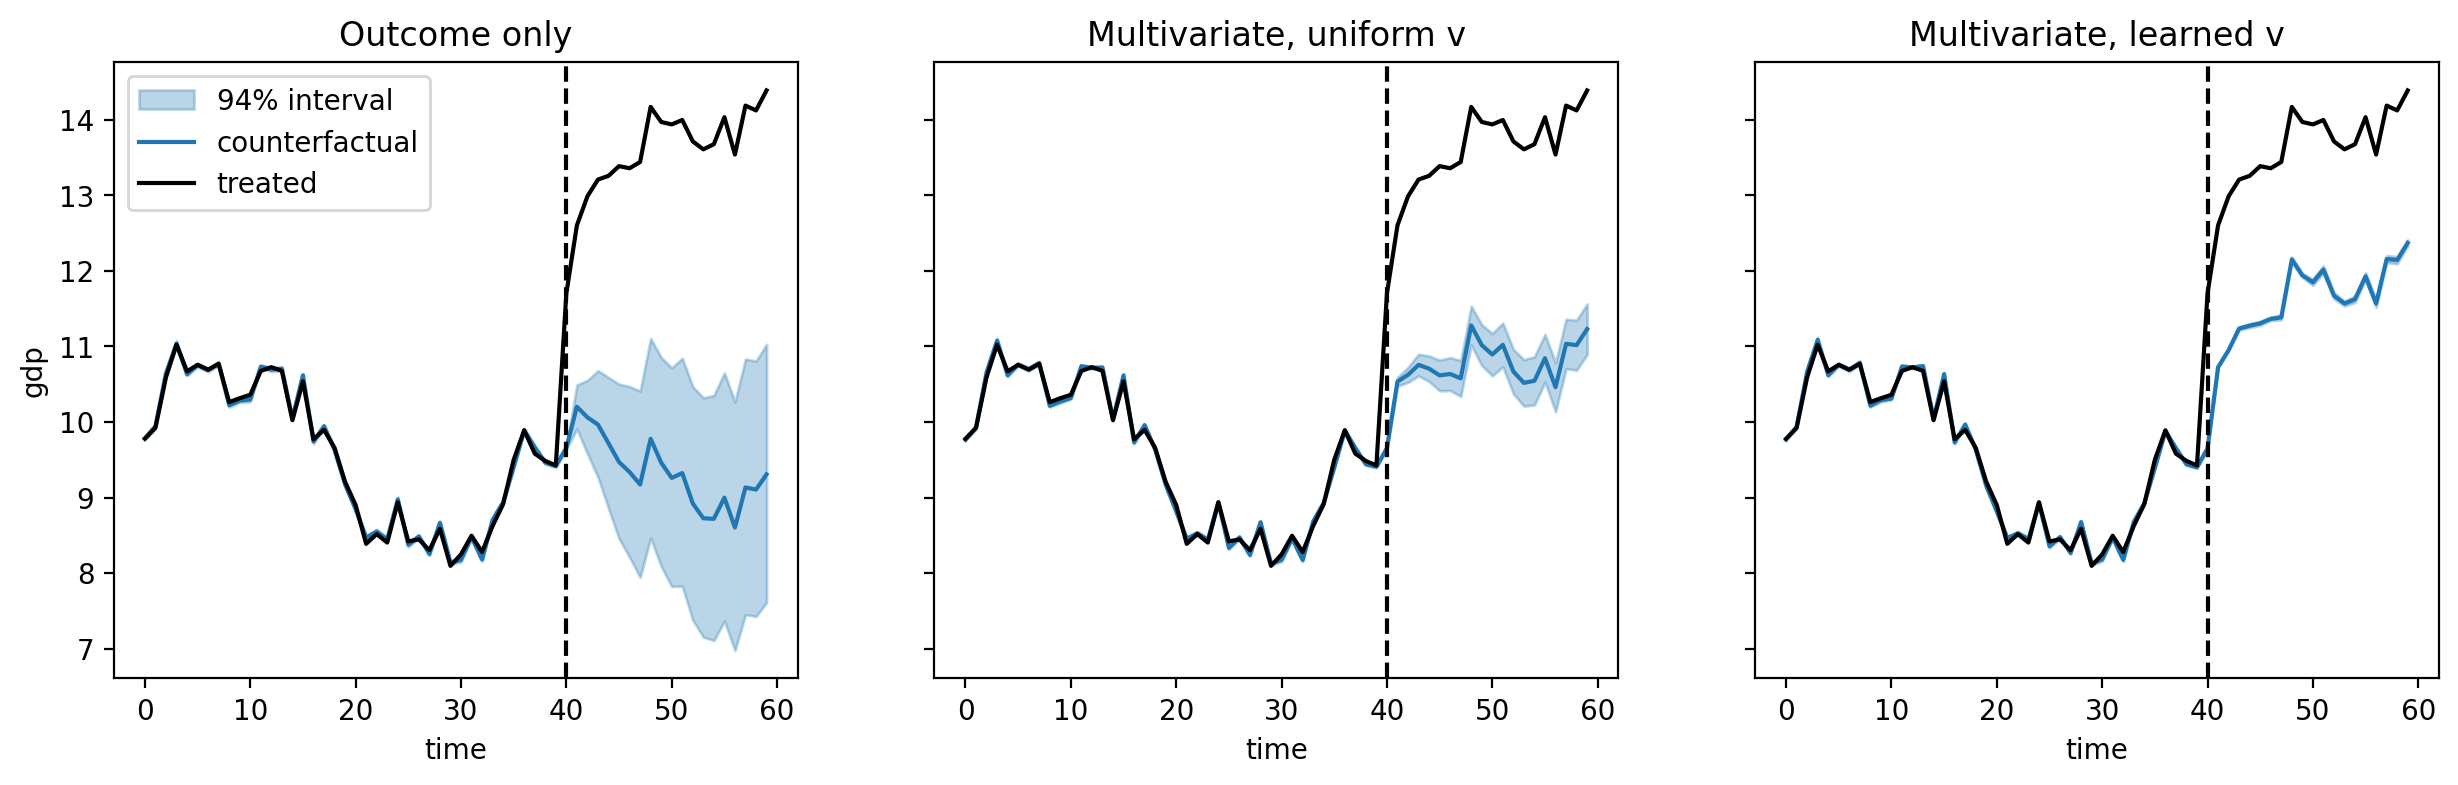

In [9]:
def plot_fit(ax, result, title):
    pred = xr.concat(
        [result.result.predictions_pre, result.result.predictions_post], dim="obs_ind"
    ).sel(treated_units="treated")
    mean = pred.mean(("chain", "draw"))
    lo, hi = pred.quantile([0.03, 0.97], dim=("chain", "draw"))
    x = pred.obs_ind.values
    ax.fill_between(x, lo, hi, color="C0", alpha=0.3, label="94% interval")
    ax.plot(x, mean, color="C0", label="counterfactual")
    ax.plot(wide.index, wide["treated"], color="k", lw=1.5, label="treated")
    ax.axvline(treatment_time, color="k", ls="--")
    ax.set(title=title, xlabel="time")


fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
plot_fit(axes[0], outcome_only, "Outcome only")
plot_fit(axes[1], uniform, "Multivariate, uniform v")
plot_fit(axes[2], learned, "Multivariate, learned v")
axes[0].set_ylabel("gdp")
axes[0].legend(loc="upper left");

In [10]:
def average_effect(result):
    impact = result.result.impact_post.sel(treated_units="treated").mean("obs_ind")
    return np.asarray(impact).ravel()


rows = []
for label, result in [
    ("Outcome only", outcome_only),
    ("Multivariate, uniform v", uniform),
    ("Multivariate, learned v", learned),
]:
    d = average_effect(result)
    rows.append(
        {
            "model": label,
            "mean effect": d.mean(),
            "94% lower": np.percentile(d, 3),
            "94% upper": np.percentile(d, 97),
            "bias vs truth": d.mean() - TRUE_EFFECT,
        }
    )
effects = pd.DataFrame(rows).set_index("model").round(2)
effects

,mean effect,94% lower,94% upper,bias vs truth
model,,,,
Outcome only,4.22,2.98,5.44,2.22
"Multivariate, uniform v",2.83,2.59,3.07,0.83
"Multivariate, learned v",2.02,1.99,2.05,0.02


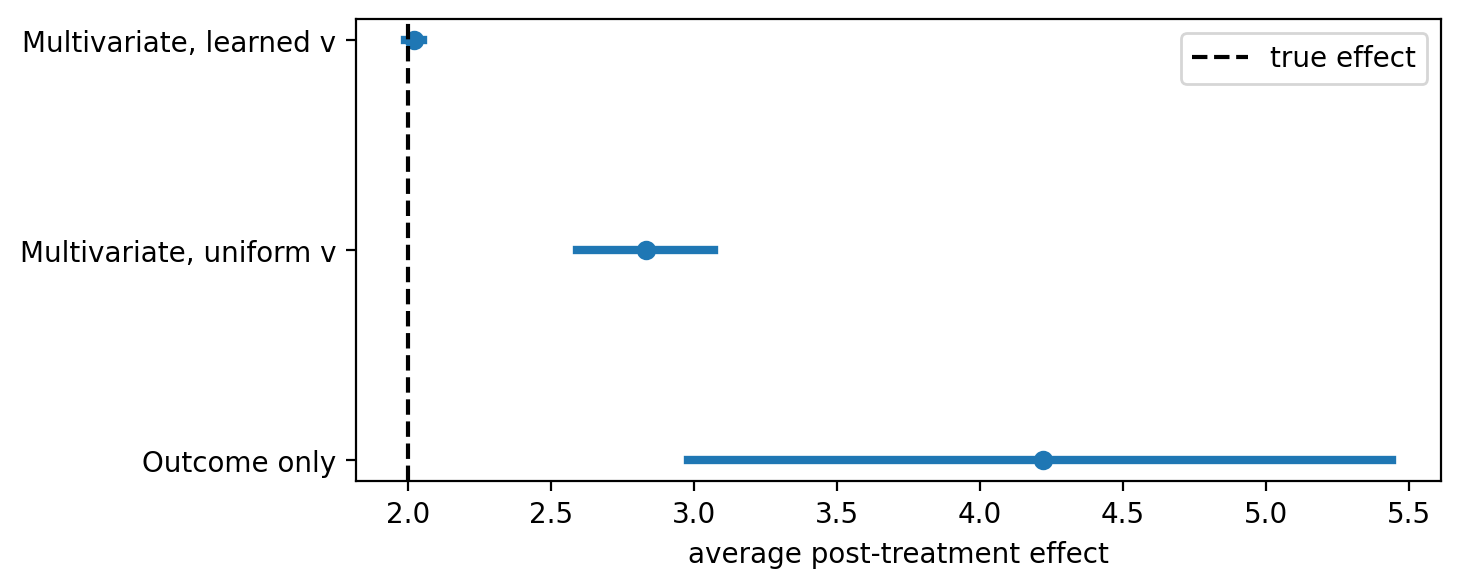

In [11]:
fig, ax = plt.subplots(figsize=(7, 3))
for i, (_label, row) in enumerate(effects.iterrows()):
    ax.plot([row["94% lower"], row["94% upper"]], [i, i], color="C0", lw=3)
    ax.plot(row["mean effect"], i, "o", color="C0")
ax.axvline(TRUE_EFFECT, color="k", ls="--", label="true effect")
ax.set(
    yticks=range(len(effects)),
    yticklabels=effects.index,
    xlabel="average post-treatment effect",
)
ax.legend();

The outcome-only model cannot see the exposure, so it builds a counterfactual with the *average* exposure and mistakes part of the post-treatment shock for a treatment effect. Matching on the predictors lets the multivariate model pick donors with the right exposure. Learning `v` also helps when some predictors are uninformative: with uniform `v`, the useless predictors count as much as the useful ones.

This is one simulated dataset, so treat it as an illustration and not as a general guarantee.

## What the weights mean

The donor weights `beta` say how much each donor contributes to the counterfactual. They sit on the simplex: non-negative and summing to one.

In [12]:
beta = (
    learned.idata["posterior"]["beta"]
    .sel(treated_units="treated")
    .mean(("chain", "draw"))
)
beta.to_series().sort_values(ascending=False).round(3)

coeffs
c6    0.249
c5    0.204
c2    0.190
c7    0.146
c3    0.126
c9    0.064
c8    0.009
c1    0.004
c0    0.004
c4    0.004
Name: beta, dtype: float64

With learned `v`, the model also estimates a weight for each predictor.

**How to read `v`:** it is *not* a measure of how important a predictor is for the outcome. The predictor likelihood has scale `sigma_feat / sqrt(K * v_k)`, so a large `v_k` means the model is allowed very little matching error on predictor `k`. The `v_k` therefore tends to be larger for predictors that the donor weights can match well, which is a statement about *match quality*. A predictor can receive a small `v` simply because it is hard to match. The `v` values are most useful as a diagnostic of which predictors the weights could reproduce.

In [13]:
v = learned.predictor_weights().mean(("chain", "draw"))
v.to_series().round(3)

features_aux
industry      0.738
exports       0.261
irrelevant    0.001
noise         0.000
Name: v, dtype: float64

## Checking the sampler

Always check the sampler diagnostics before trusting the results. Look for divergences (should be zero), R-hat close to 1 (at most 1.01) and a large effective sample size.

In [14]:
for label, result in [("learned v", learned), ("uniform v", uniform)]:
    stats = result.idata["sample_stats"].to_dataset()
    message = f"{label}: divergences = {int(stats['diverging'].sum())}"
    # A mocked sampler (used when the docs notebooks are tested) does not record
    # the tree depth, so only report it when it is there.
    if "tree_depth" in stats:
        n_deep = int((stats["tree_depth"] >= 10).sum())
        message += (
            f", max tree depth reached in {n_deep} of "
            f"{stats['tree_depth'].size} iterations"
        )
    print(message)

az.summary(learned.idata["posterior"], var_names=["beta", "v", "sigma_feat"]).round(2)

learned v: divergences = 0, max tree depth reached in 37 of 4000 iterations
uniform v: divergences = 0, max tree depth reached in 0 of 4000 iterations


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
"beta[treated, c0]",0.0042,0.0043,0.00023,0.012,2850,1975,1.00,6.8e-05,0.00011
"beta[treated, c1]",0.0044,0.0044,0.00024,0.013,2421,1912,1.00,7.6e-05,9.4e-05
"beta[treated, c2]",0.19,0.046,0.11,0.26,3364,2498,1.00,0.0008,0.00083
"beta[treated, c3]",0.126,0.056,0.037,0.22,2696,1759,1.00,0.001,0.00089
"beta[treated, c4]",0.0041,0.0041,0.00021,0.012,2514,1773,1.00,6.7e-05,9.5e-05
"beta[treated, c5]",0.204,0.078,0.079,0.33,2346,1318,1.00,0.0016,0.0016
"beta[treated, c6]",0.249,0.064,0.15,0.35,3011,2697,1.00,0.0012,0.0011
"beta[treated, c7]",0.146,0.052,0.061,0.23,2188,1908,1.00,0.0011,0.00092
"beta[treated, c8]",0.0088,0.0088,0.00054,0.026,2120,1590,1.00,0.00015,0.00023
"beta[treated, c9]",0.064,0.046,0.0059,0.15,3244,2742,1.00,0.00082,0.00078


We used `target_accept=0.99` and 1000 draws. With learned `v` the sampler can hit the maximum tree depth on some datasets. That is an efficiency warning rather than a sign of wrong results, but it means sampling takes longer. If you see it, a larger `target_accept` and more draws are the first things to try, and comparing against `v_prior="uniform"` helps tell whether `v` is the cause.

## Limitations

- Predictors must be time-varying and observed for every unit before treatment. Predictors aggregated over time, as often used with the original synthetic control method, are not supported yet.
- The counterfactual comes from the outcome only. Predictors help choose the weights, but if no donor combination can match both the outcome and the predictors, the model has to compromise between them.
- Learned `v` measures match quality, not importance for the outcome.
- This class is Bayesian only.

## References

:::{bibliography}
:filter: docname in docnames
:::